# Bipedal locomotion, part 2: convex centroidal MPC

A walking robot is, to first approximation, a lump of mass that the feet push
around. **Part 1** modelled that lump with the single-rigid-body dynamics (SRBD)
and the linear inverted pendulum, and asked *where* the center of pressure must
go to keep the center of mass (CoM) balanced. This notebook asks the dual
question: given a desired CoM behaviour, **what contact forces should each foot
apply** — and can we plan them fast enough to run on the robot?

The key structural fact is that SRBD is **linear in the contact forces**:

$$
\ddot c = \frac{1}{m}\sum_i f_i + g, \qquad
\dot L = \sum_i (p_i - c)\times f_i .
$$

Both the net force and the net moment about the CoM are *linear* maps of the
stacked foot forces $f = [f_1, \dots, f_{n_c}]$. Distributing a desired
centroidal wrench across the feet is therefore a small **convex quadratic
program** (QP) — minimize force effort subject to the wrench equality and the
friction/unilateral constraints. We build that QP and solve it directly in JAX,
then re-solve it in a loop to track a moving CoM, then show how the *same* SRBD
plant lowers to embedded C through the Jaxility deployment lane.

**By the end you will be able to:**

1. Write the centroidal wrench map $A(c)$ that turns per-foot forces into
   $[\sum f_i;\ \sum (p_i - c)\times f_i]$, and assemble the force-distribution QP.
2. Solve that QP with `jaxterity.wbc.qp.qp_solve` for double-support weight
   distribution, and watch the load redistribute as the desired CoM shifts.
3. Respect the friction box and the unilateral constraint $f_z \ge 0$, and see
   exactly where the linearised cone surrogate breaks (a real failure mode).
4. Close a short receding-horizon loop by re-solving the QP each step, and lower
   the SRBD plant to a CasADi function for the embedded `multi_contact_centroidal_mpc`
   OCP spec.

**Reading time** ~20 min. **Runtime** ~1 min on a laptop CPU (float64, no GPU).

> **Position in the series.** This is **Part 2**. It builds directly on
> **Part 1** (SRBD state $[c,\dot c, L]$, the linear inverted pendulum, the
> capture point). It precedes **Part 3**, which takes the centroidal wrench /
> contact forces planned here and maps them to *joint torques* through a
> whole-body QP (`jaxterity.wbc`) that respects the full articulated dynamics.
> Part 2 plans *what the feet should do*; Part 3 makes the *legs do it*.

> **Out of scope.** We plan forces for a **fixed contact set** (both feet in
> stance, contact points held constant over the short horizon). A *time-varying
> contact schedule* across the horizon — feet lifting and landing — is a gait
> problem we defer to a later note; here `contact_active` is constant. We also
> *describe* the embedded acados OCP build but do **not** generate the solver C:
> that step needs the compiled `acados` library (a configured
> `ACADOS_SOURCE_DIR` with built libs), which is **not available in this
> environment** — the notebook checks and reports this at runtime. We go as far
> as the dynamics lowering, which needs only CasADi.


## Setup

float64 throughout (the wrench equality residuals we check are at the
$10^{-12}$ level — float32 would drown them in rounding noise), and a fixed seed
for the one place we draw random inputs (the lowering round-trip check).

In [1]:
from jax import config
config.update("jax_enable_x64", True)  # centroidal residuals live below float32 noise

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

# Verified building blocks (see series Part 1 for srbd_dynamics).
from jaxterity.locomotion.reduced import srbd_dynamics  # centroidal SRBD, linear in forces
from jaxterity.wbc.qp import qp_solve                   # JAX QP: equality + box

# Deployment lane (Jaxility) — used near the end.
from jaxility.lowering import translate                 # JAX fn -> CasADi function
from jaxility.templates import (
    friction_box_bounds,                                # per-foot linearised-cone box
    multi_contact_centroidal_mpc,                       # embedded OCP spec builder
)

SEED = 0
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True,
                     "grid.alpha": 0.3})
print("jax x64:", jax.config.read("jax_enable_x64"))


Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


jax x64: True


## A two-foot stance

We use a humanoid-scale lump: mass $m = 35\,\text{kg}$, CoM nominally
$0.9\,\text{m}$ above the ground. Two feet sit flat on the floor, offset
$\pm 0.10\,\text{m}$ in $y$ (left/right), centred under the CoM in $x$:

| symbol | meaning | value |
|---|---|---|
| $m$ | total mass | $35\,\text{kg}$ |
| $g$ | gravity vector | $[0,0,-9.81]\,\text{m/s}^2$ |
| $p_0$ | left foot (world) | $[0,\ +0.10,\ 0]\,\text{m}$ |
| $p_1$ | right foot (world) | $[0,\ -0.10,\ 0]\,\text{m}$ |
| $\mu$ | friction coefficient | $0.7$ |
| $f_z^{\max}$ | per-foot normal-force ceiling | $400\,\text{N}$ |

The contact points are held fixed — this is a *fixed contact set*, the in-scope
case from Cell 0.

In [2]:
MASS = 35.0
G = jnp.array([0.0, 0.0, -9.81])
g_scalar = 9.81

# Foot positions in the world frame (left, then right). Held constant.
P = jnp.array([[0.0,  0.10, 0.0],   # p0: left foot
               [0.0, -0.10, 0.0]])  # p1: right foot
NC = P.shape[0]                     # number of contacts
MU = 0.7
FZ_MAX = 400.0

print(f"n_contacts = {NC},  total weight m*g = {MASS * g_scalar:.2f} N")


n_contacts = 2,  total weight m*g = 343.35 N


## The centroidal wrench map

Stack the per-foot forces into one vector $f \in \mathbb{R}^{3 n_c}$. The two
centroidal quantities are linear in $f$:

$$
\sum_i f_i = \underbrace{\begin{bmatrix} I_3 & I_3 & \cdots \end{bmatrix}}_{\text{net force rows}} f,
\qquad
\sum_i (p_i - c)\times f_i
= \underbrace{\begin{bmatrix} [p_0-c]_\times & [p_1-c]_\times & \cdots \end{bmatrix}}_{\text{net moment rows}} f,
$$

where $[v]_\times$ is the skew-symmetric cross-product matrix. Stacking force
rows on top of moment rows gives the **wrench map**

$$
A(c)\, f = \begin{bmatrix} \sum_i f_i \\[2pt] \sum_i (p_i-c)\times f_i \end{bmatrix}
\in \mathbb{R}^6,
\qquad A(c) \in \mathbb{R}^{6 \times 3 n_c}.
$$

$A$ depends on the CoM position $c$ only through the moment arms $p_i - c$. The
**desired wrench** that realises a target CoM acceleration $\ddot c_{\text{des}}$
and angular-momentum rate $\dot L_{\text{des}}$ follows straight from SRBD:

$$
w_{\text{des}} = \begin{bmatrix} m\,(\ddot c_{\text{des}} - g) \\ \dot L_{\text{des}} \end{bmatrix}.
$$

For a static hold ($\ddot c_{\text{des}} = 0$, $\dot L_{\text{des}} = 0$) the top
block is $-m g = [0,0,+m g]$: the feet must, together, push *up* with exactly
the robot's weight.

In [3]:
def skew(v):
    """Skew-symmetric cross-product matrix [v]_x, so [v]_x @ w == cross(v, w)."""
    return jnp.array([[0.0,  -v[2],  v[1]],
                      [v[2],  0.0,  -v[0]],
                      [-v[1], v[0],  0.0]])


def wrench_map(points, com):
    """A(c): stacked forces (3*nc,) -> centroidal wrench [sum F; sum (p-c) x F] (6,)."""
    top = jnp.concatenate([jnp.eye(3) for _ in range(points.shape[0])], axis=1)
    bot = jnp.concatenate([skew(points[i] - com) for i in range(points.shape[0])], axis=1)
    return jnp.concatenate([top, bot], axis=0)          # (6, 3*nc)


def desired_wrench(cddot_des, Ldot_des):
    """Desired centroidal wrench for SRBD: [m (c_ddot - g); L_dot]."""
    return jnp.concatenate([MASS * (cddot_des - G), Ldot_des])


# Sanity: skew matches jnp.cross, and a hover wrench demands +m*g of vertical force.
_v, _w = jnp.array([1.0, 2.0, 3.0]), jnp.array([-4.0, 5.0, -6.0])
assert jnp.allclose(skew(_v) @ _w, jnp.cross(_v, _w)), "skew != cross"
w_hover = desired_wrench(jnp.zeros(3), jnp.zeros(3))
assert jnp.allclose(w_hover[:3], jnp.array([0.0, 0.0, MASS * g_scalar])), "hover wrench wrong"
print("hover desired wrench [N; N·m] =", np.round(np.asarray(w_hover), 3))


hover desired wrench [N; N·m] = [  0.     0.   343.35   0.     0.     0.  ]


### Why this is the easy half of locomotion

It is worth pausing on *why* contact-force planning is tractable while the full
walking problem is not. The full problem is non-convex on two counts: the
**contact schedule** (which feet touch when) is combinatorial, and the
**rigid-body kinematics** (where the feet are, as a function of joint angles) is
nonlinear. The centroidal reduction freezes both: we fix the contact set and the
contact *points*, and we work in CoM/momentum coordinates where the dynamics are
linear. What remains — distributing a known wrench across known contact points
under conic friction limits — is **convex**.

Convexity buys three things that matter for a robot:

- **A global optimum, every time.** No local minima, no initialisation
  sensitivity. The same stance always gives the same forces.
- **Speed.** A 6-equality, 6-variable QP solves in microseconds; you can run it
  at the 1 kHz the inner loop wants.
- **Certifiable infeasibility.** When the demand *cannot* be met (Failure mode 1),
  the solver says so cleanly rather than wandering off — which is exactly the
  signal a higher layer needs to change the footstep plan.

This is the division of labour across the series: the *non-convex* decisions
(footsteps, gait timing) live in a slower outer planner; the *convex* force
distribution runs fast underneath. Part 2 is that fast convex core.


### Where the desired wrench comes from, and the center of pressure

The desired-wrench formula $w_{\text{des}} = [\,m(\ddot c_{\text{des}} - g);\ \dot
L_{\text{des}}\,]$ is just SRBD read backwards. SRBD says the forces *produce*
$\ddot c = \tfrac1m \sum f_i + g$ and $\dot L = \sum (p_i-c)\times f_i$; we want a
*particular* $\ddot c_{\text{des}}, \dot L_{\text{des}}$, so we move $m$ and $g$
across and ask the QP to find forces that hit the resulting right-hand side. The
top three rows are Newton's law for the CoM; the bottom three are the
angular-momentum balance about the CoM. Nothing more.

The quantity that decides feasibility is the **center of pressure (CoP)** — the
point on the ground where the net contact force acts with zero in-plane moment.
For a flat double-support stance the CoP must lie on the segment between the two
feet (more generally, inside the *support polygon*, the convex hull of the
contacts). The reason is exactly the unilateral constraint: a CoP outside the
support polygon would require one foot to *pull down* on the ground
($f_z < 0$) to balance the moment, which it physically cannot. So the in-scope
regime of this notebook — moderate CoM shifts, moderate accelerations — is
precisely the regime where the demanded CoP stays inside the support polygon and
the QP stays feasible. Push past it and you hit Failure mode 1.

The connection to Part 1 is direct: Part 1's *capture point* is the tool the
outer loop uses to keep the demanded CoP (and hence the desired wrench) inside
the support polygon. Part 2 assumes that job is being done and focuses on the
force distribution underneath.


## The force-distribution QP

Because the constraints are linear and the objective is a sum of squares, force
distribution is a **convex QP**. We minimise force effort — deviation from a
nominal $f_{\text{nom}}$ plus a small ridge regulariser for strict convexity —
subject to the wrench equality and a per-foot friction box:

$$
\begin{aligned}
\min_{f \in \mathbb{R}^{3 n_c}} \quad & \tfrac12 \|f - f_{\text{nom}}\|^2 + \tfrac{\epsilon}{2}\|f\|^2 \\
\text{s.t.}\quad & A(c)\, f = w_{\text{des}} && \text{(realise the centroidal wrench)} \\
& f_{z,i} \ge 0 && \text{(unilateral: feet push, never pull)} \\
& |f_{x,i}|,\ |f_{y,i}| \le \mu\, f_z^{\max} && \text{(linearised friction cone)}
\end{aligned}
$$

The friction box is the standard **pyramidal surrogate** for the friction cone
$\|f_{xy,i}\| \le \mu f_{z,i}$. We get it straight from Jaxility's
`friction_box_bounds`, which is the *same* box the embedded OCP uses — so the QP
we prototype here and the controller we deploy later share one constraint
definition. The surrogate's looseness (it bounds the tangential force by
$\mu f_z^{\max}$, a constant, not by the actual $\mu f_{z,i}$) is the source of a
failure mode we hit deliberately later.

In QP standard form ($\min \tfrac12 f^\top H f + h^\top f$ s.t. $Af=b$, $\text{lb}\le f\le\text{ub}$):
$H = (1+\epsilon) I$, $h = -f_{\text{nom}}$. `qp_solve` takes exactly this.

**A note on the solver.** `qp_solve` handles the *combination* of an equality
($Af=b$) and a box ($\text{lb}\le f\le\text{ub}$) through an ADMM loop: each
iteration solves the equality-constrained KKT system, then projects the result
back onto the box, and the penalty $\rho$ couples the two. Pure box-only or
pure equality-only problems take a faster direct path. Because we have *both*,
we pass an `admm_rho` large enough (here $\rho=80$) that the equality is tight to
the $10^{-12}$ level at the iteration budget — the residual checks below are the
proof. The ridge $\epsilon\|f\|^2$ guarantees $H\succ0$ so the KKT system is
always solvable even when the wrench under-determines the forces (more feet than
the 6-D wrench constrains).

In [4]:
def plan_forces(com, cddot_des=None, Ldot_des=None, f_nom=None,
                w_reg=1e-3, rho=80.0, iters=400):
    """Solve the convex force-distribution QP at CoM position `com`.

    Returns (f, A, w_des, (lb, ub)) where f is the stacked per-foot force (3*nc,).
    """
    cddot_des = jnp.zeros(3) if cddot_des is None else cddot_des
    Ldot_des = jnp.zeros(3) if Ldot_des is None else Ldot_des
    n = 3 * NC
    f_nom = jnp.zeros(n) if f_nom is None else f_nom

    A = wrench_map(P, com)
    w_des = desired_wrench(cddot_des, Ldot_des)
    H = (1.0 + w_reg) * jnp.eye(n)      # strictly convex
    h = -f_nom

    # Friction box from Jaxility (both feet in stance) — the same box the
    # embedded OCP uses. Stance foot: fz in [0, fz_max], |fx|,|fy| <= mu*fz_max.
    lo, hi = friction_box_bounds(tuple([True] * NC), fz_max=FZ_MAX, mu=MU)
    lb, ub = jnp.array(lo), jnp.array(hi)

    f = qp_solve(H, h, A=A, b=w_des, lb=lb, ub=ub, admm_rho=rho, admm_iters=iters)
    return f, A, w_des, (lb, ub)


# jit for the receding-horizon loop later (static iters keeps lax.scan happy).
plan_forces_jit = jax.jit(lambda com, cddot: plan_forces(com, cddot_des=cddot)[0])
print("QP planner ready. Decision variables:", 3 * NC, "(=", 3, "x", NC, "feet)")


QP planner ready. Decision variables: 6 (= 3 x 2 feet)


## (a) Double-support weight distribution

The simplest case: hold the CoM dead centre. The desired wrench is pure vertical
weight support with zero net moment. Two symmetric feet should each carry exactly
half the weight, with no tangential force.

In [5]:
com_center = jnp.array([0.0, 0.0, 0.9])
f_c, A_c, w_c, (lb, ub) = plan_forces(com_center)
forces_c = f_c.reshape(NC, 3)

residual_c = float(jnp.linalg.norm(A_c @ f_c - w_c))
sumF = forces_c.sum(axis=0)

print("per-foot force [N] (Fx, Fy, Fz):")
for i, name in enumerate(["left ", "right"]):
    print(f"  {name}: {np.round(np.asarray(forces_c[i]), 3)}")
print(f"\n  sum of forces  Fz = {float(sumF[2]):.4f} N   (m*g = {MASS*g_scalar:.4f} N)")
print(f"  wrench residual ||A f - w_des|| = {residual_c:.2e}")

# In-notebook gates (mirror the verifier).
assert residual_c < 1e-4, f"wrench not realised: {residual_c}"
assert abs(float(sumF[2]) - MASS * g_scalar) < 1e-3, "vertical force != weight"
assert abs(float(forces_c[0, 2] - forces_c[1, 2])) < 1e-3, "load not symmetric"
assert bool(jnp.all(forces_c[:, 2] >= -1e-6)), "unilateral f_z >= 0 violated"

# Cross-check against the *reference* SRBD: these forces must hold the CoM still.
state9 = jnp.concatenate([com_center, jnp.zeros(3), jnp.zeros(3)])
dx = srbd_dynamics(state9, forces_c, P, mass=MASS)
assert float(jnp.max(jnp.abs(dx[3:9]))) < 1e-4, "SRBD says CoM would accelerate"
print(f"\n  SRBD check: max|c_ddot, L_dot| = {float(jnp.max(jnp.abs(dx[3:9]))):.2e}  -> CoM held")


per-foot force [N] (Fx, Fy, Fz):
  left : [  0.     -0.    171.675]
  right: [  0.      0.    171.675]

  sum of forces  Fz = 343.3500 N   (m*g = 343.3500 N)
  wrench residual ||A f - w_des|| = 4.89e-32

  SRBD check: max|c_ddot, L_dot| = 1.40e-33  -> CoM held


## (b) Shifting the CoM laterally → load redistribution

Now sweep the desired CoM laterally in $y$ from $-0.08$ to $+0.08\,\text{m}$ and
re-solve the QP at each position. The left foot sits at $y=+0.10$; as the CoM
moves toward it, the moment-balance equality forces the **left foot to take more
load and the right foot less**, monotonically — exactly what you feel shifting
your weight foot to foot. The total vertical force stays pinned at $m g$
throughout (the equality demands it).

In [6]:
ys = jnp.linspace(-0.08, 0.08, 17)
left_fz, right_fz, shift_res = [], [], []
forces_by_y = []
for y in ys:
    f_y, A_y, w_y, _ = plan_forces(jnp.array([0.0, float(y), 0.9]))
    fr = f_y.reshape(NC, 3)
    forces_by_y.append(np.asarray(fr))
    left_fz.append(float(fr[0, 2]))
    right_fz.append(float(fr[1, 2]))
    shift_res.append(float(jnp.linalg.norm(A_y @ f_y - w_y)))

left_fz, right_fz = np.array(left_fz), np.array(right_fz)
ys_np = np.asarray(ys)

# Gates: monotone redistribution, conserved total, all residuals tiny, all f_z>=0.
assert np.all(np.diff(left_fz) >= -1e-3), "left load not monotone increasing"
assert np.all(np.diff(right_fz) <= 1e-3), "right load not monotone decreasing"
assert abs((left_fz + right_fz).mean() - MASS * g_scalar) < 1e-2, "total Fz drifted"
assert max(shift_res) < 1e-4, f"a shift case did not realise its wrench: {max(shift_res)}"
assert np.all(left_fz >= -1e-6) and np.all(right_fz >= -1e-6), "f_z < 0 somewhere"
print(f"max wrench residual over the sweep = {max(shift_res):.2e}")
print(f"left foot load span: {left_fz[0]:.1f} -> {left_fz[-1]:.1f} N")
print(f"total Fz (mean over sweep) = {(left_fz+right_fz).mean():.3f} N  (m*g = {MASS*g_scalar:.3f})")


max wrench residual over the sweep = 5.72e-14
left foot load span: 34.3 -> 309.0 N
total Fz (mean over sweep) = 343.350 N  (m*g = 343.350)


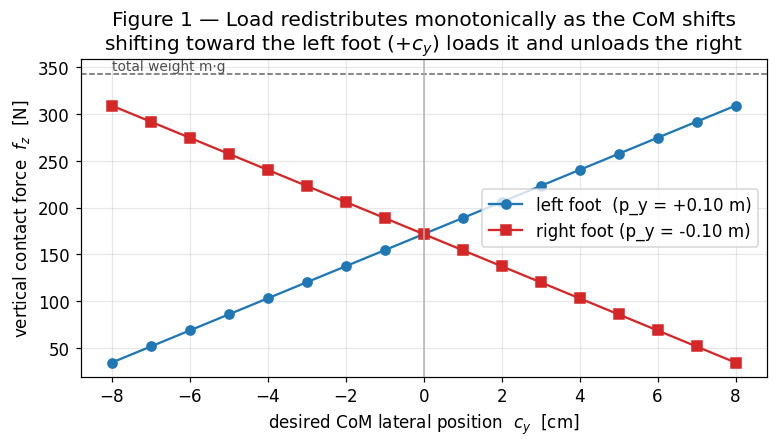

In [7]:
# Figure 1: per-foot vertical force vs lateral CoM position.
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(ys_np * 100, left_fz, "o-", color="#1f77b4", label="left foot  (p_y = +0.10 m)")
ax.plot(ys_np * 100, right_fz, "s-", color="#d62728", label="right foot (p_y = -0.10 m)")
ax.axhline(MASS * g_scalar, ls="--", color="0.4", lw=1)
ax.text(ys_np[0] * 100, MASS * g_scalar + 4, "total weight m·g", color="0.3", fontsize=9)
ax.axvline(0, color="0.7", lw=1)
ax.set_xlabel("desired CoM lateral position  $c_y$  [cm]")
ax.set_ylabel("vertical contact force  $f_z$  [N]")
ax.set_title("Figure 1 — Load redistributes monotonically as the CoM shifts\n"
             "shifting toward the left foot ($+c_y$) loads it and unloads the right")
ax.legend(loc="center right")
fig.tight_layout()
plt.show()


### Centred vs shifted: per-foot force bars

A direct before/after of all three force components. Centred, the feet split the
weight evenly with no tangential force. Shifted $+6\,\text{cm}$ toward the left
foot, the left $f_z$ climbs and the right drops, while $f_x, f_y$ stay near zero
(a pure $y$-shift with feet on flat ground demands no tangential force — the
moment is balanced by *redistributing the normal forces*, not by shearing).

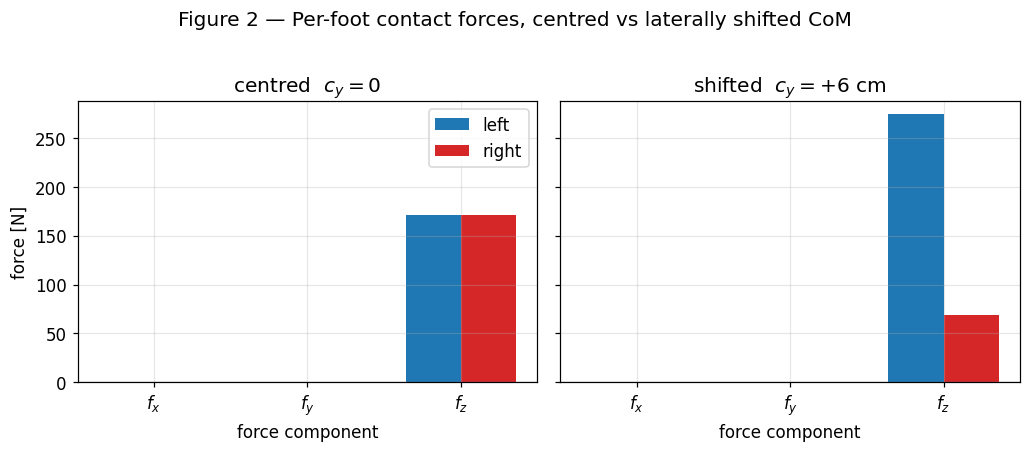

centred:  left fz=171.7  right fz=171.7 N
shifted:  left fz=274.7  right fz=68.7 N


In [8]:
# Pick the +6 cm shifted case from the sweep.
idx_shift = int(np.argmin(np.abs(ys_np - 0.06)))
forces_shift = forces_by_y[idx_shift]

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.0), sharey=True)
comp_labels = ["$f_x$", "$f_y$", "$f_z$"]
xpos = np.arange(3)
width = 0.36
for ax, forces, title in [(axes[0], np.asarray(forces_c), "centred  $c_y=0$"),
                          (axes[1], forces_shift, f"shifted  $c_y=+6$ cm")]:
    ax.bar(xpos - width/2, forces[0], width, color="#1f77b4", label="left")
    ax.bar(xpos + width/2, forces[1], width, color="#d62728", label="right")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xticks(xpos); ax.set_xticklabels(comp_labels)
    ax.set_title(title)
    ax.set_xlabel("force component")
axes[0].set_ylabel("force [N]")
axes[0].legend()
fig.suptitle("Figure 2 — Per-foot contact forces, centred vs laterally shifted CoM", y=1.02)
fig.tight_layout()
plt.show()

print(f"centred:  left fz={forces_c[0,2]:.1f}  right fz={forces_c[1,2]:.1f} N")
print(f"shifted:  left fz={forces_shift[0,2]:.1f}  right fz={forces_shift[1,2]:.1f} N")


## Achieved vs desired wrench

The QP equality constraint should make the *achieved* wrench $A f^\star$ match
the *desired* wrench $w_{\text{des}}$ to solver tolerance, for every case in the
sweep. The bars below overlay achieved on desired for the centred and shifted
cases; they coincide to the eye, and the residual line confirms it numerically
($<10^{-4}\,$N across the whole sweep).

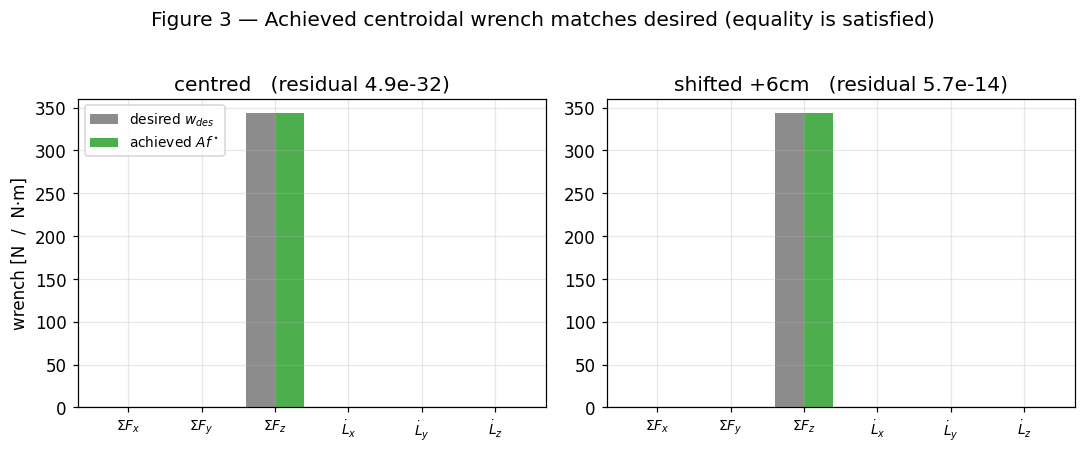

In [9]:
# Achieved vs desired, for centred and +6cm cases.
cases = [("centred", com_center), ("shifted +6cm", jnp.array([0.0, 0.06, 0.9]))]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
wrench_labels = ["$\\Sigma F_x$", "$\\Sigma F_y$", "$\\Sigma F_z$",
                 "$\\dot L_x$", "$\\dot L_y$", "$\\dot L_z$"]
xpos = np.arange(6)
for ax, (label, com) in zip(axes, cases):
    f_k, A_k, w_k, _ = plan_forces(com)
    achieved = np.asarray(A_k @ f_k)
    desired = np.asarray(w_k)
    ax.bar(xpos - 0.2, desired, 0.4, color="0.55", label="desired $w_{des}$")
    ax.bar(xpos + 0.2, achieved, 0.4, color="#2ca02c", alpha=0.85, label="achieved $A f^\\star$")
    ax.set_xticks(xpos); ax.set_xticklabels(wrench_labels, fontsize=9)
    ax.set_title(f"{label}   (residual {float(np.linalg.norm(achieved-desired)):.1e})")
    ax.axhline(0, color="0.6", lw=0.8)
axes[0].set_ylabel("wrench [N  /  N·m]")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Figure 3 — Achieved centroidal wrench matches desired (equality is satisfied)", y=1.02)
fig.tight_layout()
plt.show()


Notice the bottom three wrench components ($\dot L_x, \dot L_y, \dot L_z$)
are essentially zero in both cases above. That is expected and instructive: a
*static* CoM shift on flat ground demands no rate of change of angular momentum —
the feet rebalance the *normal* forces to move the CoP, and the moment about the
CoM stays balanced throughout. The angular-momentum rows of the wrench map earn
their keep only when you demand a turning moment or a dynamic manoeuvre (Exercise
5), or when the feet are at different heights. They are in the formulation
because balance ultimately *is* an angular-momentum problem (Orin 2013) — this
static case simply does not exercise them.

## (c) Friction cone / box: the solution lives inside it

The unilateral constraint ($f_z \ge 0$) and the friction box together carve out
the feasible tangential force at each foot. We visualise the $(f_y, f_z)$ slice:
the true friction cone is the wedge $|f_y| \le \mu f_z$; the **box surrogate**
is the rectangle $f_z \in [0, f_z^{\max}]$, $|f_y| \le \mu f_z^{\max}$. The
planned solution for several lateral-shift cases is plotted on top — every point
sits inside *both* the box and the true cone for these moderate shifts.

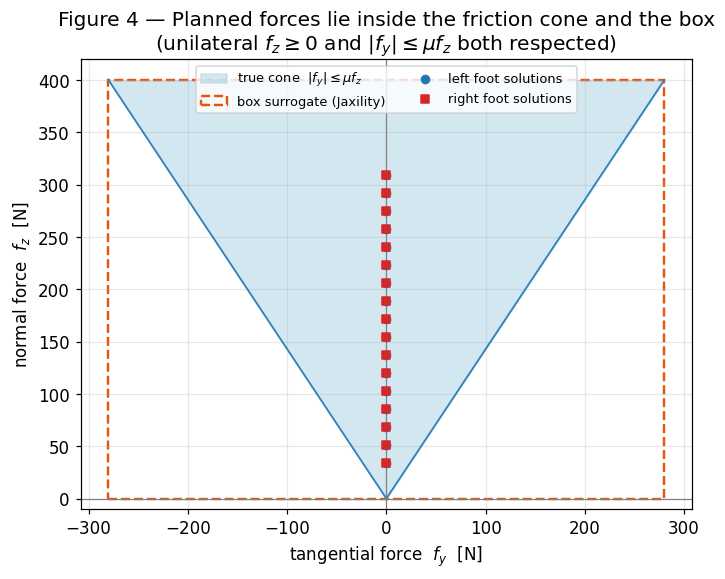

all swept solutions inside the true friction cone:  OK


In [10]:
fig, ax = plt.subplots(figsize=(6.6, 5.4))

# True friction cone (wedge) in the (f_y, f_z) plane: |f_y| <= mu * f_z.
fz_line = np.linspace(0, FZ_MAX, 50)
ax.fill_betweenx(fz_line, -MU * fz_line, MU * fz_line, color="#9ecae1", alpha=0.45,
                 label=r"true cone  $|f_y|\leq\mu f_z$")
ax.plot(MU * fz_line, fz_line, color="#3182bd", lw=1.2)
ax.plot(-MU * fz_line, fz_line, color="#3182bd", lw=1.2)

# Box surrogate: rectangle |f_y| <= mu*fz_max, f_z in [0, fz_max].
box = Rectangle((-MU * FZ_MAX, 0.0), 2 * MU * FZ_MAX, FZ_MAX,
                fill=False, ec="#e6550d", lw=1.6, ls="--",
                label="box surrogate (Jaxility)")
ax.add_patch(box)

# Plot planned (f_y, f_z) for both feet across the lateral sweep.
fy_all = np.array([[forces_by_y[k][i, 1] for k in range(len(ys))] for i in range(NC)])
fz_all = np.array([[forces_by_y[k][i, 2] for k in range(len(ys))] for i in range(NC)])
ax.scatter(fy_all[0], fz_all[0], c="#1f77b4", s=28, zorder=5, label="left foot solutions")
ax.scatter(fy_all[1], fz_all[1], c="#d62728", s=28, marker="s", zorder=5, label="right foot solutions")

ax.axhline(0, color="0.5", lw=0.8)
ax.axvline(0, color="0.5", lw=0.8)
ax.set_xlabel("tangential force  $f_y$  [N]")
ax.set_ylabel("normal force  $f_z$  [N]")
ax.set_xlim(-MU * FZ_MAX * 1.1, MU * FZ_MAX * 1.1)
ax.set_ylim(-10, FZ_MAX * 1.05)
ax.set_title("Figure 4 — Planned forces lie inside the friction cone and the box\n"
             "(unilateral $f_z\\geq 0$ and $|f_y|\\leq\\mu f_z$ both respected)")
ax.legend(loc="upper center", fontsize=8.5, ncol=2)
fig.tight_layout()
plt.show()

# Gate: every planned foot force is inside the TRUE cone for the sweep.
for k in range(len(ys)):
    for i in range(NC):
        fxy = float(np.linalg.norm(forces_by_y[k][i, :2]))
        fz_i = float(forces_by_y[k][i, 2])
        assert fxy <= MU * fz_i + 1e-6, "solution left the true friction cone"
print("all swept solutions inside the true friction cone:  OK")


## (d) Closing the loop: a short receding-horizon QP-MPC

Re-solving the QP every control step *is* a (single-shooting, one-step) MPC over
the centroidal model. We drive the CoM laterally to a $5\,\text{cm}$ target with
a simple PD law that sets the desired acceleration $\ddot c_{\text{des}}$; the QP
turns that desired acceleration into feasible contact forces; we integrate the
*reference* SRBD forward one step and repeat. This is the control loop a real
deployment runs — except a real deployment plans over a *horizon* (the embedded
`multi_contact_centroidal_mpc` spec we build next), not one step at a time.

In [11]:
dt = 0.02
steps = 150
y_target = 0.05
kp, kd = 60.0, 16.0

c = jnp.array([0.0, 0.0, 0.9])
cdot = jnp.zeros(3)
traj_y, traj_fz_l, traj_fz_r = [], [], []
for k in range(steps):
    cddot_des = jnp.array([
        0.0,
        kp * (y_target - float(c[1])) - kd * float(cdot[1]),         # PD on y
        kp * (0.9 - float(c[2])) - kd * float(cdot[2]),              # hold height
    ])
    f_k = plan_forces_jit(c, cddot_des)
    fr = f_k.reshape(NC, 3)
    st9 = jnp.concatenate([c, cdot, jnp.zeros(3)])
    dxk = srbd_dynamics(st9, fr, P, mass=MASS)   # reference SRBD = the plant
    c = c + dt * dxk[0:3]
    cdot = cdot + dt * dxk[3:6]
    traj_y.append(float(c[1]))
    traj_fz_l.append(float(fr[0, 2]))
    traj_fz_r.append(float(fr[1, 2]))

t = np.arange(steps) * dt
final_err = abs(traj_y[-1] - y_target)
assert final_err < 5e-3, f"MPC did not reach target: {final_err}"
assert max(abs(np.array(traj_y))) < 0.12, "CoM trajectory blew up"
print(f"final CoM_y = {traj_y[-1]:.4f} m   target = {y_target} m   error = {final_err:.4e} m")


final CoM_y = 0.0500 m   target = 0.05 m   error = 5.8791e-10 m


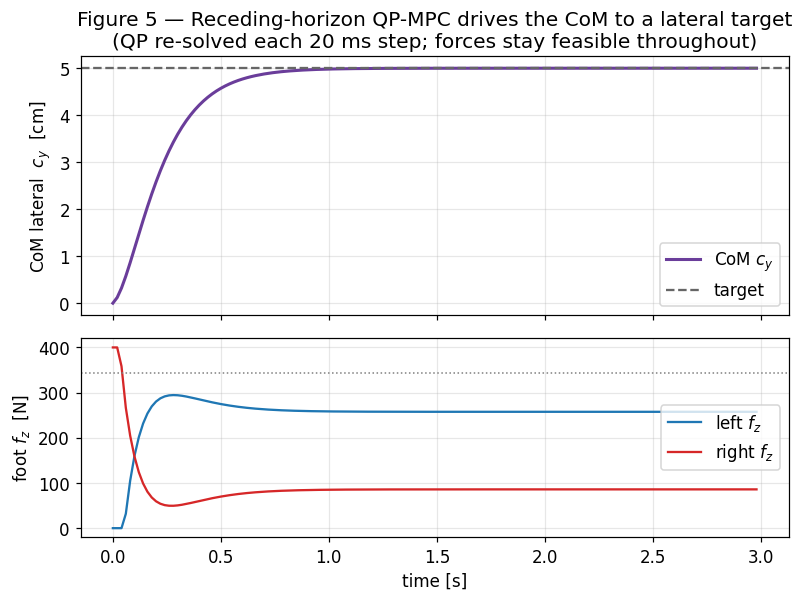

In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.4, 5.6), sharex=True,
                               gridspec_kw={"height_ratios": [1.3, 1]})
ax1.plot(t, np.array(traj_y) * 100, color="#6a3d9a", lw=2, label="CoM $c_y$")
ax1.axhline(y_target * 100, ls="--", color="0.4", label="target")
ax1.set_ylabel("CoM lateral  $c_y$  [cm]")
ax1.set_title("Figure 5 — Receding-horizon QP-MPC drives the CoM to a lateral target\n"
              "(QP re-solved each 20 ms step; forces stay feasible throughout)")
ax1.legend(loc="lower right")

ax2.plot(t, traj_fz_l, color="#1f77b4", label="left $f_z$")
ax2.plot(t, traj_fz_r, color="#d62728", label="right $f_z$")
ax2.axhline(MASS * g_scalar, ls=":", color="0.5", lw=1)
ax2.set_xlabel("time [s]")
ax2.set_ylabel("foot $f_z$  [N]")
ax2.legend(loc="center right")
fig.tight_layout()
plt.show()


### Reading Figure 5

Two things to notice. **Top:** the CoM slides smoothly to the $5\,\text{cm}$
target with no overshoot — the PD law sets a desired acceleration, and the QP
finds forces that produce *exactly* that acceleration on the reduced model
(because the wrench equality is met every step). The tracking is as good as the
PD gains, no better and no worse; the force layer is transparent. **Bottom:** the
two feet trade vertical load during the move — the foot the CoM travels toward
takes more — and settle at the new asymmetric split that holds the shifted CoM.
The dotted line is total weight $m g$; the two $f_z$ traces always sum to it,
because that is what the equality demands at every instant.

This loop is *single-step* MPC: one QP, one integration, repeat. A deployed
controller plans over a **horizon** instead — predicting several steps ahead so
it can anticipate a footstep or a disturbance — which is precisely the OCP the
next two cells assemble for embedded export.


## From prototype to embedded: lowering the SRBD plant

The QP above is the *prototype*. To deploy, the same SRBD dynamics must become a
C function the embedded solver can call. Jaxility's `translate` traces a JAX
function and emits a CasADi expression graph, gating every primitive through its
coverage table.

One practical wrinkle worth stating plainly: the reference `srbd_dynamics`
computes $\sum_i f_i$ with a `reduce_sum` over the contact axis, and
`reduce_sum` is **outside Jaxility's lowering subset**. So we write the
two-contact SRBD with the force sum *unrolled* ($f_0 + f_1$) — numerically
identical, but using only supported primitives (add, sub, mul, div, slice,
cross via concatenate). This is the same plant the embedded OCP expects: contact
points baked in as constants, state $[c,\dot c, L]\in\mathbb{R}^9$, control
$[f_0, f_1]\in\mathbb{R}^{6}$.

In [13]:
_MASS, _P0, _P1, _G = MASS, P[0], P[1], G

def srbd_for_deploy(state, u):
    """Two-contact SRBD with the force-sum unrolled (lowering-friendly).

    state = [c(3), c_dot(3), L(3)];  u = [f0(3), f1(3)].  Avoids reduce_sum so it
    stays inside Jaxility's supported smooth-op subset.
    """
    c = state[0:3]
    cdot = state[3:6]
    f0, f1 = u[0:3], u[3:6]
    cddot = (f0 + f1) / _MASS + _G
    Ldot = jnp.cross(_P0 - c, f0) + jnp.cross(_P1 - c, f1)
    return jnp.concatenate([cdot, cddot, Ldot])


srbd_cf = translate(srbd_for_deploy, in_shapes=((9,), (3 * NC,)),
                    dtype="float64", target_family="cortex-m4",
                    name="srbd_centroidal")

print("lowering succeeded.")
print("  input shapes :", srbd_cf.input_shapes)
print("  primitives used:", sorted(srbd_cf.primitives_used))

# Gates: translate succeeded with a non-empty primitive set, and the lowered C
# function reproduces both the JAX source and the reference srbd_dynamics exactly.
assert len(srbd_cf.primitives_used) > 0, "no primitives lowered"
assert srbd_cf.input_shapes == ((9,), (3 * NC,)), "wrong I/O shapes"

rng = np.random.default_rng(SEED)
st = jnp.asarray(rng.normal(size=9))
uu = jnp.asarray(rng.normal(size=3 * NC))
cas_out = np.asarray(srbd_cf.fn(st, uu)).ravel()
jax_out = np.asarray(srbd_for_deploy(st, uu))
ref_out = np.asarray(srbd_dynamics(st, uu.reshape(NC, 3), P, mass=MASS))
assert np.max(np.abs(cas_out - jax_out)) < 1e-9, "CasADi != JAX"
assert np.max(np.abs(jax_out - ref_out)) < 1e-9, "unrolled SRBD != reference"
print(f"\n  CasADi vs JAX max abs err     : {np.max(np.abs(cas_out - jax_out)):.2e}")
print(f"  unrolled vs reference SRBD err: {np.max(np.abs(jax_out - ref_out)):.2e}")


lowering succeeded.
  input shapes : ((9,), (6,))
  primitives used: ['add', 'broadcast_in_dim', 'concatenate', 'div', 'mul', 'slice', 'squeeze', 'sub']

  CasADi vs JAX max abs err     : 0.00e+00
  unrolled vs reference SRBD err: 0.00e+00


## The embedded OCP spec

`multi_contact_centroidal_mpc` assembles the full optimal-control problem spec
around the lowered SRBD plant: state dimension $n_x = 9$, control dimension
$n_u = 3 n_c = 6$, stage costs $Q, R$, and — crucially — the *same*
`friction_box_bounds` we used in the prototype QP, now as per-foot control
bounds. Flipping an entry of `contact_active` to `False` pins that foot's force
to zero, so the one spec covers any stance.

This is where the firewall to the heavy toolchain sits. The spec is pure
data — it builds here with nothing but CasADi. **Generating and compiling the
solver C, by contrast, requires the compiled acados library** (a configured
`ACADOS_SOURCE_DIR`). The cell below checks for it: in this environment the
acados *Python template* may import, but the *compiled library* is not
configured, so we build and inspect the spec and stop short of the exporter.

In [14]:
spec = multi_contact_centroidal_mpc(
    srbd_cf,
    Q=(10.0,) * 9,                       # penalise CoM pose/vel/momentum error
    R=(0.01,) * (3 * NC),                # light penalty on force effort
    initial_com_state=(0.0, 0.0, 0.9, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0),
    contact_active=tuple([True] * NC),   # double support
    fz_max=FZ_MAX,
    mu=MU,
)

print("OcpTemplateSpec built:")
print(f"  n_x (state cost length) = {len(spec.state_cost)}   (expected 9: c, c_dot, L)")
print(f"  n_u (input cost length) = {len(spec.input_cost)}   (expected {3*NC}: stacked forces)")
print(f"  input upper bounds      = {spec.input_upper}")
print(f"  input lower bounds      = {spec.input_lower}")

# Gates.
assert len(spec.state_cost) == 9, "nx != 9"
assert len(spec.input_cost) == 3 * NC, "nu != 3*nc"
expected_box = friction_box_bounds(tuple([True] * NC), fz_max=FZ_MAX, mu=MU)[1]
assert spec.input_upper == tuple(expected_box), "friction box not propagated to OCP"

# Demonstrate the swing-foot case: flipping contact_active zeroes that foot.
spec_swing = multi_contact_centroidal_mpc(
    srbd_cf, Q=(1.0,) * 9, R=(0.1,) * (3 * NC),
    initial_com_state=(0.0,) * 9, contact_active=(True, False),
    fz_max=FZ_MAX, mu=MU)
assert spec_swing.input_upper[3:6] == (0.0, 0.0, 0.0), "swing foot not pinned to zero"
print("\n  swing-foot test: right foot force bounds pinned to",
      spec_swing.input_upper[3:6], "-> zero force, as expected")

# Honest runtime probe: is the *compiled* acados library available for solver-C export?
import os, importlib.util
acados_py = importlib.util.find_spec("acados_template") is not None
acados_lib = bool(os.environ.get("ACADOS_SOURCE_DIR"))
print(f"\n  acados Python template importable : {acados_py}")
print(f"  ACADOS_SOURCE_DIR configured       : {acados_lib}")
if acados_lib:
    print("  -> compiled acados available; the exporter could run (not invoked in this notebook).")
else:
    print("  -> compiled acados NOT configured here; solver-C generation is correctly skipped.")


OcpTemplateSpec built:
  n_x (state cost length) = 9   (expected 9: c, c_dot, L)
  n_u (input cost length) = 6   (expected 6: stacked forces)
  input upper bounds      = (280.0, 280.0, 400.0, 280.0, 280.0, 400.0)
  input lower bounds      = (-280.0, -280.0, 0.0, -280.0, -280.0, 0.0)

  swing-foot test: right foot force bounds pinned to (0.0, 0.0, 0.0) -> zero force, as expected

  acados Python template importable : True
  ACADOS_SOURCE_DIR configured       : False
  -> compiled acados NOT configured here; solver-C generation is correctly skipped.


## Failure modes

**1. Infeasible wrench when the CoP leaves the support polygon.** The wrench
equality $A(c) f = w_{\text{des}}$ has a solution with $f_z \ge 0$ on every foot
*only if* the required center of pressure lies inside the support polygon (here,
the segment between the two feet). Demand a moment that would put the CoP outside
that segment and the only way to balance it is a *negative* normal force — which
the unilateral constraint forbids. The QP then cannot satisfy both the equality
and the box, and the wrench residual jumps off zero. The fix is upstream: keep
the *desired* CoM/CoP inside the support polygon (that is what Part 1's capture
point is for), or change the contact set.

**2. Cone-linearisation error (the box is looser than the true cone).** The
friction box bounds the tangential force by $\mu f_z^{\max}$ — a *constant*
ceiling — not by $\mu f_{z,i}$, the actual per-solution normal force. For
moderate demands the two agree (Figure 4), but ask for a large lateral CoM
acceleration and the QP can return a force that is inside the *box* yet outside
the *true cone*: it would slip on the real robot. The cell below provokes exactly
this. The honest fixes are a tighter (octagonal) cone linearisation, or coupling
the tangential bound to the live $f_z$ (a second-order cone constraint, which
needs an SOCP rather than the box QP).

In [15]:
# Provoke the cone-linearisation failure: demand a large lateral CoM acceleration.
cddot_hard = jnp.array([0.0, 6.0, 0.0])   # 6 m/s^2 sideways — aggressive
f_hard, A_hard, w_hard, _ = plan_forces(com_center, cddot_des=cddot_hard)
fr_hard = f_hard.reshape(NC, 3)
res_hard = float(jnp.linalg.norm(A_hard @ f_hard - w_hard))

print(f"aggressive lateral demand c_ddot_y = 6 m/s^2")
print(f"  wrench residual = {res_hard:.2f}  N  (large -> the box QP cannot realise it)")
for i, name in enumerate(["left", "right"]):
    fxy = float(np.linalg.norm(fr_hard[i, :2]))
    fz_i = float(fr_hard[i, 2])
    cone_slack = MU * fz_i - fxy
    flag = "INSIDE cone" if cone_slack >= -1e-6 else "OUTSIDE true cone (would slip!)"
    print(f"  {name}: |f_xy|={fxy:6.1f}  mu*f_z={MU*fz_i:6.1f}  -> {flag}")

print("\nThis is expected: the box surrogate caps |f_xy| at mu*fz_max, so for a")
print("demand this large it returns a force that the *true* cone would reject.")


aggressive lateral demand c_ddot_y = 6 m/s^2
  wrench residual = 159.41  N  (large -> the box QP cannot realise it)


  left: |f_xy|= 105.0  mu*f_z=   0.0  -> OUTSIDE true cone (would slip!)
  right: |f_xy|= 105.0  mu*f_z= 280.0  -> INSIDE cone

This is expected: the box surrogate caps |f_xy| at mu*fz_max, so for a
demand this large it returns a force that the *true* cone would reject.


## Exercises

1. **Three contacts.** Add a third contact point (e.g. a hand on a rail at
   $[0.2, 0, 0.8]$) and extend `wrench_map` and `friction_box_bounds` to
   $n_c = 3$. Confirm the QP now has a 2-dimensional null space (the wrench is
   6-D, the forces are 9-D) and that the regulariser picks the minimum-norm
   distribution.

2. **Nominal-force tracking.** Pass a non-zero `f_nom` (e.g. last step's
   solution) and watch the QP produce *smoother* force trajectories in the
   receding-horizon loop. Quantify the reduction in $\|\Delta f\|$ between steps.

3. **Tighten the cone.** Replace the 4-facet box with an 8-facet (octagonal)
   linearised cone as a set of inequality rows $C f \le 0$ (you will need a QP
   path that takes general inequalities, or fold them into the box by rotating
   the force frame). Re-run the aggressive-demand cell from *Failure modes* and
   show the residual shrinks.

4. **Single support.** Set `contact_active=(True, False)` in `plan_forces` (build
   a swing-aware box). Show that holding the CoM over the *stance* foot is
   feasible but holding it over the lifted foot is not — the QP residual reports
   the infeasibility.

5. **Add angular momentum.** Demand a non-zero $\dot L_{\text{des}}$ (a turning
   moment) and observe how the feet trade tangential force to produce it. At what
   $\dot L$ does the true cone bind?


## References

- D. E. Orin, A. Goswami, S.-H. Lee. *Centroidal dynamics of a humanoid robot.*
  Autonomous Robots, 2013. — The centroidal momentum framework: $[c,\dot c, L]$
  and why the angular-momentum term is the one that matters for balance.
- H. Dai, A. Valenzuela, R. Tedrake. *Whole-body motion planning with centroidal
  dynamics and full kinematics.* Humanoids, 2014. — Centroidal dynamics as the
  reduced model in a trajectory-optimization stack.
- J. Carpentier, N. Mansard. *Multicontact locomotion of legged robots.*
  IEEE T-RO, 2018. — Centroidal contact-force planning and the convex structure
  exploited here.
- R. Verschueren et al. *acados — a modular open-source framework for fast
  embedded optimal control.* Mathematical Programming Computation, 2022. — The
  embedded SQP/QP solver the `multi_contact_centroidal_mpc` spec targets.
- S. Caron, Q.-C. Pham, Y. Nakamura. *Stability of surface contacts for humanoid
  robots* (CoP / support-area conditions), ICRA 2015. — The feasibility boundary
  behind Failure mode 1.


## Next steps

**Part 3 — whole-body control.** Part 2 planned *what the feet should do*: a
centroidal wrench and the per-foot contact forces that realise it. Part 3 makes
the *legs actually do it*. The planned contact forces become reference targets in
a **whole-body QP** over the full articulated dynamics
(`jaxterity.wbc`): it maps the desired CoM/contact behaviour to **joint torques**
subject to the robot's true mass matrix, joint limits, and contact Jacobians,
with task priorities (CoM task, contact task, posture task). The centroidal layer
here is the reduced model that keeps that whole-body QP small and real-time.

The deployment thread also continues: the `OcpTemplateSpec` built above is the
input to Jaxility's acados exporter, which (with the toolchain installed) emits
the self-contained C controller and its attestation manifest — the sim-to-deploy
round-trip closed by construction.
